# TDE 04 — Modelo Final: Predição do Valor de Imóveis em São Paulo

**Integrantes do grupo:**

| Nome | Matrícula |
|---|---|
| Thalys Eduardo Ferreira Cazuza | 20241180148 |
| Arthur Rodrigues de Carvalho | 20241130037 |
| Ramon Porfírio Macedo | 20241130023 |

## O problema

Queremos prever o **preço de venda** e o **preço de aluguel** de apartamentos em São Paulo a partir das
características do imóvel (tamanho, quartos, vagas, condomínio...) e da sua localização.
É um problema de **regressão**: a resposta do modelo é um número (o preço em reais).

## Evolução do projeto

| Etapa | O que fizemos |
|---|---|
| **TDE 01** | Definição do problema, análise da base (mostrou que tamanho e localização são os fatores mais ligados ao preço) e uma Regressão Linear feita "na mão" com NumPy |
| **TDE 03** | **Baseline** (modelo simples que serve de ponto de comparação): Regressão Linear e Regressão Polinomial (grau 2), sem otimizações |
| **TDE 04** (este notebook) | Melhorias nos dados, busca de hiperparâmetros, **SVM**, **Rede Neural** e modelos **não vistos em sala**, comparando tudo com o baseline |

## Objetivo desta etapa

1. **Melhorar o baseline** do TDE 03, seguindo os "próximos passos" que listamos lá: normalizar as variáveis,
   usar regularização, incluir o distrito e escolher os hiperparâmetros com validação cruzada;
2. Testar **SVM** e **Redes Neurais**;
3. Testar modelos que **não vimos em sala**: **KNN** e **Gradient Boosting** (em sala, o boosting foi visto só com o
   AdaBoost). Também usamos a **Random Forest**, vista na aula de Ensembles;
4. **Comparar todos os modelos** com as mesmas métricas e nos mesmos dados de teste, e escolher o **modelo final**.

## Dataset

- Fonte: [São Paulo Real Estate - Sale / Rent - April 2019 (Kaggle)](https://www.kaggle.com/datasets/argonalyst/sao-paulo-real-estate-sale-rent-april-2019)
- Arquivo: `sao-paulo-properties-april-2019.csv` (deixe na mesma pasta deste notebook; no Google Colab, faça o upload do arquivo antes de rodar).
- Tempo para rodar o notebook inteiro: cerca de 4 minutos em um computador com 12 núcleos lógicos; no Google Colab gratuito (2 núcleos) deve demorar bem mais (a busca de hiperparâmetros é a parte mais demorada).
- Os resultados salvos neste notebook foram gerados com as versões de bibliotecas mostradas na seção 1. Com outras
  versões (por exemplo, no Google Colab) os números podem mudar um pouco, principalmente o da Regressão Polinomial do
  baseline, que sem normalização é numericamente instável. Testamos também com pandas 2.2 e scikit-learn 1.6: os
  modelos finais escolhidos foram os mesmos.

## 1. Bibliotecas e configurações

In [1]:
import time
import warnings

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# Modelos
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

# Esconde o aviso de "convergência" da rede neural, para a saída ficar mais limpa
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Versões usadas (os números podem mudar um pouco com outras versões)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__)

pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [2]:
# Cores usadas nos gráficos
AZUL = "#2a78d6"
LARANJA = "#eb6834"
CINZA = "#8a8984"
CINZA_CLARO = "#cfcec8"
CINZA_ESCURO = "#52514e"

# Estilo simples para todos os gráficos: sem bordas em cima/à direita e grade bem clara
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})


def reais(valor):
    """Formata um valor no padrão brasileiro: R$ 1.234.567"""
    return "R$ " + f"{valor:,.0f}".replace(",", ".")


def reais_curto(valor, posicao=None):
    """Versão curta para os eixos dos gráficos: R$ 1,5 mi / R$ 300 mil"""
    if abs(valor) >= 1_000_000:
        return f"R$ {valor / 1_000_000:.1f} mi".replace(".", ",").replace(",0 ", " ")
    if abs(valor) >= 1_000:
        return f"R$ {valor / 1_000:.1f} mil".replace(".", ",").replace(",0 ", " ")
    return f"R$ {valor:.0f}"


print("Exemplos:", reais(1234567), "|", reais_curto(1_500_000), "|", reais_curto(300_000), "|", reais_curto(2_500))

Exemplos: R$ 1.234.567 | R$ 1,5 mi | R$ 300 mil | R$ 2,5 mil


## 2. Carregando os dados

In [3]:
dados = pd.read_csv("sao-paulo-properties-april-2019.csv")
print("Linhas e colunas:", dados.shape)
dados.head()

Linhas e colunas: (13640, 16)


,Price,Condo,Size,Rooms,Toilets,Suites,Parking,Elevator,Furnished,Swimming Pool,New,District,Negotiation Type,Property Type,Latitude,Longitude
0,930,220,47,2,2,1,1,0,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.543138,-46.479486
1,1000,148,45,2,2,1,1,0,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.550239,-46.480718
2,1000,100,48,2,2,1,1,0,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.542818,-46.485665
3,1000,200,48,2,2,1,1,0,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.547171,-46.483014
4,1300,410,55,2,2,1,1,1,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.525025,-46.482436


## 3. Análise da base

### 3.1 O que tem na base

Cada linha é um **anúncio de apartamento** em São Paulo (abril de 2019).

| Coluna | Significado |
|---|---|
| `Price` | preço de venda **ou** de aluguel (é o que queremos prever) |
| `Condo` | valor do condomínio (R\$) |
| `Size` | tamanho (m²) |
| `Rooms`, `Toilets`, `Suites` | quantidade de quartos, banheiros e suítes |
| `Parking` | vagas de garagem |
| `Elevator`, `Furnished`, `Swimming Pool`, `New` | tem elevador / é mobiliado / tem piscina / é novo (1 = sim, 0 = não) |
| `District` | distrito (bairro) |
| `Negotiation Type` | `sale` (venda) ou `rent` (aluguel) |
| `Property Type` | tipo do imóvel (todos são `apartment`) |
| `Latitude`, `Longitude` | localização |

In [4]:
# Venda e aluguel estão misturados na mesma base
print(dados["Negotiation Type"].value_counts())
print()
print("Tipos de imóvel:", list(dados["Property Type"].unique()))
print("Quantidade de distritos:", dados["District"].nunique())
print("Valores faltando na base inteira:", dados.isnull().sum().sum())

Negotiation Type
rent    7228
sale    6412
Name: count, dtype: int64

Tipos de imóvel: ['apartment']
Quantidade de distritos: 96
Valores faltando na base inteira: 0


### 3.2 Limpeza: coordenadas erradas

Já no TDE 03 encontramos imóveis com latitude/longitude **fora da cidade de São Paulo** (a maioria com as duas
iguais a 0). Esses imóveis atrapalham os modelos, então os removemos usando a mesma regra do TDE 03.

Também separamos venda e aluguel: os preços estão em escalas completamente diferentes (centenas de milhares de
reais na venda e milhares no aluguel), então treinamos **um modelo para cada tipo**, como nas etapas anteriores.

In [5]:
# Coordenadas dentro da cidade de São Paulo (mesma regra do TDE 03)
dentro_de_sp = dados["Latitude"].between(-24.1, -23.3) & dados["Longitude"].between(-47.0, -46.3)

print("Imóveis com coordenada fora de SP:", (~dentro_de_sp).sum())
print("  - com latitude e longitude iguais a 0:", ((dados["Latitude"] == 0) & (dados["Longitude"] == 0)).sum())

dados = dados[dentro_de_sp].copy()
print("Imóveis que sobraram:", len(dados))

# Nome do distrito sem o "/São Paulo" do final (ex.: "Moema/São Paulo" -> "Moema")
dados["Distrito"] = dados["District"].str.replace("/São Paulo", "")

dados_venda = dados[dados["Negotiation Type"] == "sale"]
dados_aluguel = dados[dados["Negotiation Type"] == "rent"]
print("Venda:", len(dados_venda), "| Aluguel:", len(dados_aluguel))

Imóveis com coordenada fora de SP: 986
  - com latitude e longitude iguais a 0: 881
Imóveis que sobraram: 12654
Venda: 5942 | Aluguel: 6712


### 3.3 Como o preço está distribuído?

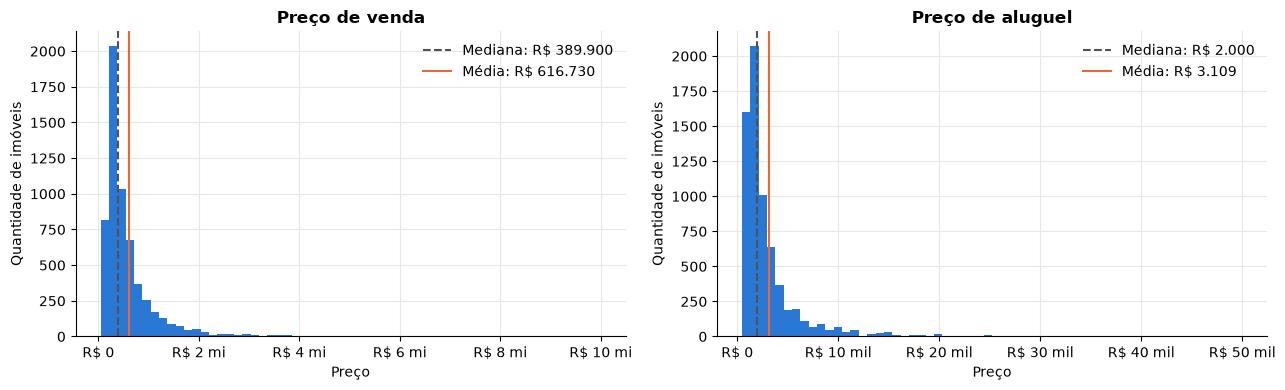

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

for eixo, tipo, df in zip(eixos, ["Venda", "Aluguel"], [dados_venda, dados_aluguel]):
    eixo.hist(df["Price"], bins=60, color=AZUL)
    eixo.axvline(df["Price"].median(), color=CINZA_ESCURO, linestyle="--", linewidth=1.5,
                 label=f"Mediana: {reais(df['Price'].median())}")
    eixo.axvline(df["Price"].mean(), color=LARANJA, linewidth=1.5,
                 label=f"Média: {reais(df['Price'].mean())}")
    eixo.set_title(f"Preço de {tipo.lower()}")
    eixo.set_xlabel("Preço")
    eixo.set_ylabel("Quantidade de imóveis")
    eixo.xaxis.set_major_formatter(FuncFormatter(reais_curto))
    eixo.legend(frameon=False)

plt.tight_layout()
plt.show()

A maioria dos imóveis tem preço mais baixo e poucos são muito caros: a distribuição tem uma **cauda longa à
direita** (assimetria positiva). Esses poucos imóveis caros puxam a **média para cima da mediana**. Eles também são
os mais difíceis de prever, porque existem poucos exemplos deles para o modelo aprender.

### 3.4 Onde ficam os imóveis mais caros?

Para comparar regiões usamos o **preço do m²** (preço ÷ tamanho). Assim um apartamento grande não parece "caro"
só por ser grande.

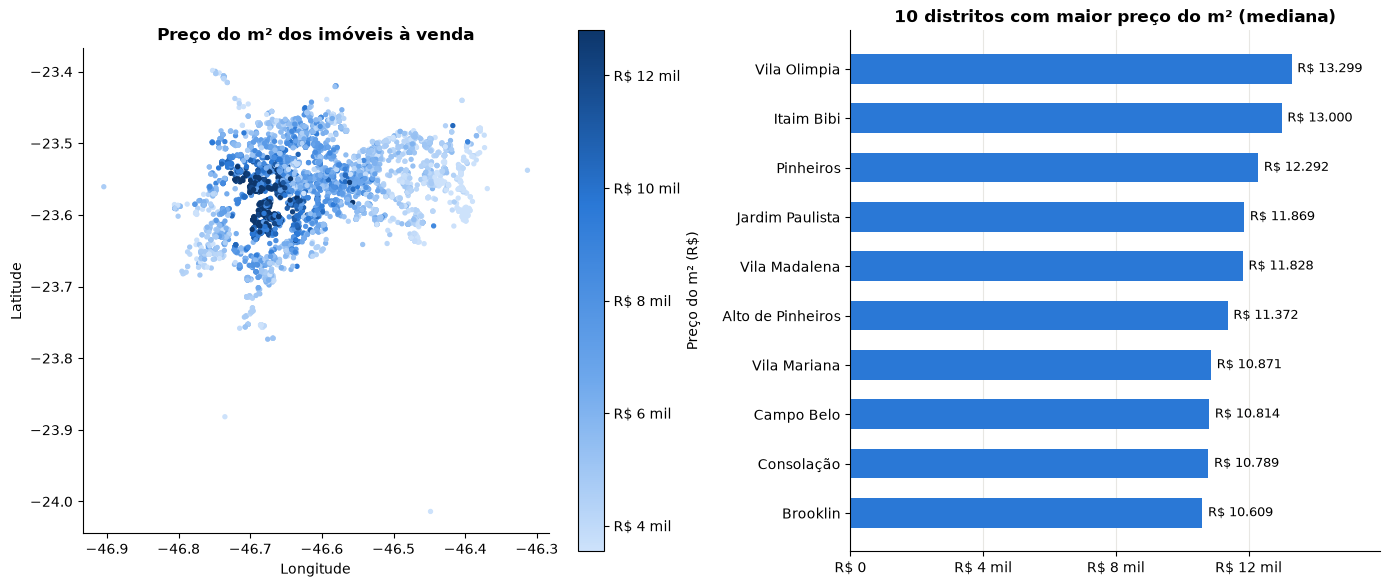

In [7]:
preco_m2 = dados_venda["Price"] / dados_venda["Size"]

fig, eixos = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.1, 1]})

# Mapa: cada ponto é um imóvel à venda, colorido pelo preço do m² (azul mais escuro = mais caro)
azuis = LinearSegmentedColormap.from_list("azuis", ["#cde2fb", "#6da7ec", "#2a78d6", "#0d366b"])
mapa = eixos[0].scatter(dados_venda["Longitude"], dados_venda["Latitude"], c=preco_m2, cmap=azuis,
                        vmin=preco_m2.quantile(0.05), vmax=preco_m2.quantile(0.95), s=8)
fig.colorbar(mapa, ax=eixos[0], label="Preço do m² (R$)", format=FuncFormatter(reais_curto))
eixos[0].set_title("Preço do m² dos imóveis à venda")
eixos[0].set_xlabel("Longitude")
eixos[0].set_ylabel("Latitude")
eixos[0].set_aspect("equal")
eixos[0].grid(False)

# Os 10 distritos com maior preço do m² (só distritos com pelo menos 30 imóveis à venda)
resumo = preco_m2.groupby(dados_venda["Distrito"]).agg(["median", "count"])
top10 = resumo[resumo["count"] >= 30].sort_values("median").tail(10)

barras = eixos[1].barh(top10.index, top10["median"], color=AZUL, height=0.6)
eixos[1].bar_label(barras, labels=[reais(v) for v in top10["median"]], padding=4, fontsize=9)
eixos[1].set_title("10 distritos com maior preço do m² (mediana)")
eixos[1].xaxis.set_major_formatter(FuncFormatter(reais_curto))
eixos[1].xaxis.set_major_locator(MaxNLocator(4))
eixos[1].margins(x=0.2)
eixos[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

O mapa mostra **regiões** com preço do m² bem mais alto (a sudoeste do centro: Vila Olímpia, Itaim Bibi,
Pinheiros e Jardim Paulista) e preços mais baixos nas bordas da cidade, principalmente na zona leste e no extremo sul. Ou seja, **a localização importa muito**, mas de um jeito que não é
uma reta: o preço não cresce simplesmente "quanto mais ao norte" ou "quanto mais a leste".

### 3.5 Quais variáveis andam junto com o preço?

A **correlação** vai de -1 a 1: perto de 1, a variável e o preço sobem juntos; perto de -1, quando a variável sobe o
preço desce; perto de 0, não há relação **linear**.

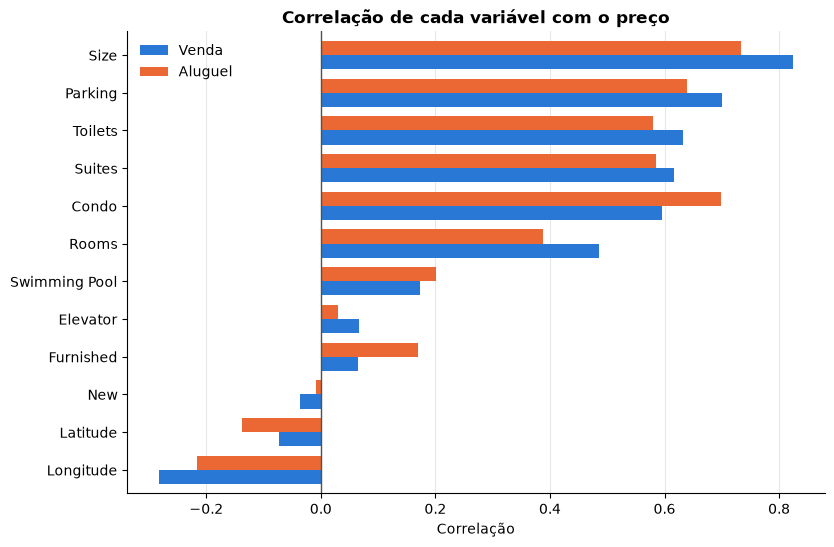

,Venda,Aluguel
Size,0.82,0.73
Parking,0.70,0.64
Toilets,0.63,0.58
Suites,0.62,0.58
Condo,0.60,0.70
Rooms,0.49,0.39
Swimming Pool,0.17,0.20
Elevator,0.07,0.03
Furnished,0.06,0.17
New,-0.04,-0.01


In [8]:
# As 12 variáveis numéricas que usamos desde o TDE 01
colunas_originais = ["Condo", "Size", "Rooms", "Toilets", "Suites", "Parking",
                     "Elevator", "Furnished", "Swimming Pool", "New",
                     "Latitude", "Longitude"]

correlacao = pd.DataFrame({
    "Venda": dados_venda[colunas_originais].corrwith(dados_venda["Price"]),
    "Aluguel": dados_aluguel[colunas_originais].corrwith(dados_aluguel["Price"]),
}).sort_values("Venda")

eixo = correlacao.plot.barh(figsize=(9, 6), color=[AZUL, LARANJA], width=0.75)
eixo.axvline(0, color=CINZA_ESCURO, linewidth=1)
eixo.set_title("Correlação de cada variável com o preço")
eixo.set_xlabel("Correlação")
eixo.grid(axis="y", visible=False)
eixo.legend(frameon=False)
plt.show()

correlacao.sort_values("Venda", ascending=False).round(2)

**Tamanho, vagas, banheiros, suítes e condomínio** são as variáveis mais ligadas ao preço. Repare que
**latitude e longitude têm correlação fraca** (entre -0,28 e -0,07), embora o mapa mostre que a localização importa muito.
Isso acontece porque a correlação só mede relações em **linha reta**, e o efeito da localização é por **regiões**.
Essa é a principal pista para esta etapa: precisamos de (1) uma forma melhor de representar a localização e
(2) modelos que aprendam relações **não lineares**.

## 4. Preparação dos dados

### 4.1 Novidade: o distrito como variável (one-hot encoding)

No baseline, a localização entrava só pela latitude e pela longitude. Agora incluímos também o **distrito**. Como os
modelos só entendem números, usamos **one-hot encoding**: cada distrito vira uma coluna, com **1** se o imóvel é
daquele distrito e **0** se não é. Exemplo:

| Distrito | Distrito_Moema | Distrito_Pinheiros | Distrito_Sé |
|---|---|---|---|
| Moema | 1 | 0 | 0 |
| Pinheiros | 0 | 1 | 0 |
| Sé | 0 | 0 | 1 |

In [9]:
distritos = pd.get_dummies(dados["Distrito"], prefix="Distrito", dtype=int)
dados = pd.concat([dados, distritos], axis=1)

colunas_distrito = list(distritos.columns)
colunas_tde04 = colunas_originais + colunas_distrito   # variáveis usadas pelos modelos novos

print("Colunas de distrito criadas:", len(colunas_distrito))
print("Variáveis no baseline (TDE 03):", len(colunas_originais))
print("Variáveis nos modelos do TDE 04:", len(colunas_tde04))

Colunas de distrito criadas: 96
Variáveis no baseline (TDE 03): 12
Variáveis nos modelos do TDE 04: 108


### 4.2 Divisão em treino e teste

Usamos **exatamente a mesma divisão do TDE 03** (80% treino, 20% teste, `random_state=42`). Assim os modelos novos
são testados **nos mesmos imóveis** que o baseline e a comparação é justa.

Guardamos as tabelas em dicionários para usar um `for` e não repetir o código: `treino["Venda"]` é a tabela de
treino dos imóveis à venda, `teste["Aluguel"]` é a tabela de teste do aluguel, e assim por diante.

In [10]:
# Separa venda e aluguel de novo (agora com as colunas de distrito)
dados_venda = dados[dados["Negotiation Type"] == "sale"]
dados_aluguel = dados[dados["Negotiation Type"] == "rent"]

treino, teste = {}, {}
treino["Venda"], teste["Venda"] = train_test_split(dados_venda, test_size=0.2, random_state=42)
treino["Aluguel"], teste["Aluguel"] = train_test_split(dados_aluguel, test_size=0.2, random_state=42)

for tipo in ["Venda", "Aluguel"]:
    print(f"{tipo:8s} -> treino: {len(treino[tipo])} | teste: {len(teste[tipo])}")

Venda    -> treino: 4753 | teste: 1189
Aluguel  -> treino: 5369 | teste: 1343


## 5. Métricas de avaliação

As mesmas do TDE 03, sempre calculadas nos **dados de teste** (que o modelo não viu no treino):

| Métrica | O que mede | Melhor quando |
|---|---|---|
| **MAE** (Erro Absoluto Médio) | Em média, quantos reais o modelo erra. **É a nossa métrica principal**, porque é fácil de entender | Menor |
| **MSE** (Erro Quadrático Médio) | Média dos erros ao quadrado; pune muito os erros grandes | Menor |
| **RMSE** (Raiz do MSE) | O MSE de volta para reais. Como vem dos erros ao quadrado, também pesa mais os erros grandes | Menor |
| **R²** (Coeficiente de Determinação) | Quanto da variação do preço o modelo explica (1 = perfeito, 0 = igual a chutar a média). Também usa os erros ao quadrado | Maior (até 1) |

$$MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE} \qquad
R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

## 6. Como treinamos os modelos novos

### 6.1 Normalização

As variáveis estão em escalas muito diferentes: `Size` vai de dezenas a centenas de m², `Condo` chega a milhares
de reais e `Latitude` fica perto de -23,5. Modelos que calculam **distâncias** (SVM) ou fazem **somas com pesos** (Rede Neural,
Ridge) ficam desequilibrados: a variável com números maiores "fala mais alto". O `StandardScaler` coloca cada
variável na mesma escala (média 0 e desvio padrão 1):

$$z = \frac{x - \text{média}}{\text{desvio padrão}}$$

Fazemos o mesmo com o **preço** durante o treino (com o `TransformedTargetRegressor`) e o modelo converte a
previsão de volta para reais no final. A média e o desvio são calculados **só com os dados de treino**.
Para os modelos de árvores (Random Forest e Gradient Boosting) a normalização não muda nada, mas também não
atrapalha, então usamos o mesmo processo para todos.

### 6.2 Hiperparâmetros e validação cruzada

**Hiperparâmetros** são as "configurações" que escolhemos **antes** do treino (exemplo: quantas árvores a Random
Forest tem). Para escolher sem "colar" olhando o teste, usamos **validação cruzada** com o `GridSearchCV`:

1. Listamos alguns valores para cada hiperparâmetro (a "grade");
2. Para cada combinação, dividimos o **treino** em 5 partes: treinamos com 4 e medimos o MAE na parte que sobrou.
   Repetimos 5 vezes, trocando a parte de validação:

```
Rodada 1: [VALIDA] [treina] [treina] [treina] [treina]
Rodada 2: [treina] [VALIDA] [treina] [treina] [treina]
Rodada 3: [treina] [treina] [VALIDA] [treina] [treina]
Rodada 4: [treina] [treina] [treina] [VALIDA] [treina]
Rodada 5: [treina] [treina] [treina] [treina] [VALIDA]
```

3. A combinação com o **menor MAE médio** nas 5 rodadas vence (esse valor aparece na tabela como **MAE validação**);
4. O modelo é treinado de novo com **todo o treino** e só então é avaliado no **teste**.

O **modelo final** é escolhido pelo MAE validação. O teste fica guardado para a "nota final", como uma prova que o
modelo nunca viu.

### 6.3 A função `treinar`

Usamos um **Pipeline**: uma sequência de passos (normalizar → modelo) que o scikit-learn trata como um modelo só.
Para o `GridSearchCV` achar um hiperparâmetro lá dentro, o nome leva o "caminho" separado por `__` (dois
sublinhados): `regressor__modelo__C` quer dizer "o C do passo modelo". A função monta esse nome sozinha.

Para não repetir código, a função abaixo faz tudo isso para **venda e aluguel** e guarda as métricas de cada modelo.
No baseline ela é usada **sem** normalização e **sem** hiperparâmetros, para reproduzir exatamente o TDE 03.

In [11]:
resultados = []          # métricas de cada modelo (vira a tabela de comparação)
previsoes = {}           # previsões no teste:  previsoes[("Venda", "Random Forest")]
modelos_treinados = {}   # modelos já treinados: modelos_treinados[("Venda", "Random Forest")]


def treinar(nome, modelo, parametros=None, colunas=None, etapa="TDE 04", normalizar=True):
    """Treina o modelo para venda e para aluguel e guarda as métricas no teste."""
    if parametros is None:
        parametros = {}            # nenhum hiperparâmetro para testar
    if colunas is None:
        colunas = colunas_tde04    # variáveis originais + distrito

    if normalizar:
        # Normaliza as variáveis (X) e o preço (y) durante o treino
        modelo = TransformedTargetRegressor(
            regressor=Pipeline([("normalizar", StandardScaler()), ("modelo", modelo)]),
            transformer=StandardScaler(),
        )
        # O GridSearchCV precisa do "caminho" até o hiperparâmetro dentro do pipeline
        parametros = {"regressor__modelo__" + nome_param: valores for nome_param, valores in parametros.items()}

    for tipo in ["Venda", "Aluguel"]:
        X_treino, y_treino = treino[tipo][colunas], treino[tipo]["Price"]
        X_teste, y_teste = teste[tipo][colunas], teste[tipo]["Price"]

        # Validação cruzada com 5 partes, testando todas as combinações da grade
        inicio = time.time()
        busca = GridSearchCV(modelo, parametros, cv=5, scoring="neg_mean_absolute_error", n_jobs=-1)
        busca.fit(X_treino, y_treino)
        tempo = time.time() - inicio

        melhor_modelo = busca.best_estimator_   # já treinado de novo com todo o treino
        previsto = melhor_modelo.predict(X_teste)

        previsoes[(tipo, nome)] = previsto
        modelos_treinados[(tipo, nome)] = melhor_modelo

        mse = mean_squared_error(y_teste, previsto)
        resultados.append({
            "Tipo": tipo,
            "Etapa": etapa,
            "Modelo": nome,
            "MAE validação": -busca.best_score_,   # o GridSearchCV devolve o MAE com sinal negativo
            "MAE": mean_absolute_error(y_teste, previsto),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R²": r2_score(y_teste, previsto),
            "R² treino": r2_score(y_treino, melhor_modelo.predict(X_treino)),
            "Tempo (s)": tempo,
        })

        melhores = {p.replace("regressor__modelo__", ""): v for p, v in busca.best_params_.items()}
        texto = f" | melhores hiperparâmetros: {melhores}" if melhores else ""
        print(f"{tipo:8s} MAE no teste = {reais(resultados[-1]['MAE']):>11s} | R² = {resultados[-1]['R²']:.2f}{texto}")

## 7. Baseline (TDE 03)

Primeiro reproduzimos o baseline **exatamente como no TDE 03**: só as 12 variáveis originais, sem normalização e sem
ajustar hiperparâmetros. Também incluímos a **referência** (sempre chutar o preço médio do treino), que não é um
algoritmo de verdade e serve só para mostrar se os modelos aprenderam alguma coisa.

In [12]:
print("Referência (chutar a média)")
treinar("Referência (média)", DummyRegressor(strategy="mean"),
        colunas=colunas_originais, etapa="Referência", normalizar=False)

print("\nRegressão Linear")
treinar("Regressão Linear", LinearRegression(),
        colunas=colunas_originais, etapa="Baseline (TDE 03)", normalizar=False)

print("\nRegressão Polinomial (grau 2)")
treinar("Regressão Polinomial", make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
        colunas=colunas_originais, etapa="Baseline (TDE 03)", normalizar=False)

Referência (chutar a média)


Venda    MAE no teste =  R$ 397.450 | R² = -0.00


Aluguel  MAE no teste =    R$ 1.989 | R² = -0.00

Regressão Linear


Venda    MAE no teste =  R$ 176.168 | R² = 0.75
Aluguel  MAE no teste =    R$ 1.137 | R² = 0.63

Regressão Polinomial (grau 2)


Venda    MAE no teste =  R$ 154.654 | R² = 0.69
Aluguel  MAE no teste =    R$ 1.074 | R² = 0.66


Os números são **iguais aos do TDE 03** (MAE de R\$ 176.168 e R\$ 154.654 na venda, R\$ 1.137 e R\$ 1.074 no
aluguel), o que confirma que estamos usando os mesmos dados de teste.

A referência aparece com R² = -0.00: é um número negativo muito pequeno, na prática 0 (chutar a média dá exatamente
R² = 0). Nas saídas do Python o separador decimal é o ponto (0.75 = 0,75).

## 8. Modelos novos (TDE 04)

Todos os modelos desta seção usam as **108 variáveis** (12 originais + 96 distritos), a **normalização** e a
**busca de hiperparâmetros** com validação cruzada.

### 8.1 Ridge: Regressão Polinomial com regularização (visto em sala)

No TDE 03, a Regressão Polinomial errou feio em um imóvel de 620 m² (previu R\$ 12,6 milhões para um imóvel de
R\$ 3,85 milhões). Nossa **hipótese** era que alguns pesos tinham ficado grandes demais. A **regularização Ridge**
coloca uma "multa" nos pesos grandes (na seção 10.2 vemos se isso resolveu esse caso). Em vez de minimizar só o erro,
o modelo minimiza:

$$\text{soma dos erros ao quadrado} + \alpha \cdot \text{soma dos pesos ao quadrado}$$

Quanto maior o **alpha (α)**, mais o modelo é "segurado" e menos ele exagera. O `PolynomialFeatures` cria os
quadrados e as combinações das variáveis, normalizamos de novo (os quadrados ficam em escalas novas) e o `Ridge`
faz a regressão. A validação cruzada escolhe o alpha.

In [13]:
ridge_polinomial = make_pipeline(PolynomialFeatures(degree=2), StandardScaler(), Ridge())

treinar("Ridge (Polinomial + regularização)", ridge_polinomial,
        {"ridge__alpha": [100, 1000, 10000]})   # "ridge__alpha" = o alpha do passo "ridge"

Venda    MAE no teste =  R$ 127.500 | R² = 0.76 | melhores hiperparâmetros: {'ridge__alpha': 1000}


Aluguel  MAE no teste =      R$ 841 | R² = 0.67 | melhores hiperparâmetros: {'ridge__alpha': 1000}


### 8.2 SVM para regressão (SVR)

A SVM que vimos em sala separa classes. Para prever números existe a versão **SVR** (*Support Vector Regression*):

- o modelo traça uma curva com um **"tubo"** em volta dela, que vai de **epsilon (ε)** acima até ε abaixo da curva;
- erros **dentro do tubo** são ignorados; só os imóveis **fora do tubo** (os vetores de suporte) puxam a curva;
- o **kernel RBF** permite que a curva se dobre, ou seja, aprenda relações não lineares;
- o hiperparâmetro **C** diz o quanto o modelo é punido pelos pontos fora do tubo (C alto = tenta acertar mais,
  com mais risco de decorar o treino).

Como a SVM trabalha com distâncias entre imóveis, a normalização é obrigatória aqui. Como o preço também está
normalizado, ε = 0,1 quer dizer "0,1 desvio padrão do preço".

In [14]:
treinar("SVM (SVR)", SVR(kernel="rbf"),
        {"C": [1, 10, 100], "epsilon": [0.01, 0.1]})

Venda    MAE no teste =  R$ 108.743 | R² = 0.84 | melhores hiperparâmetros: {'C': 10, 'epsilon': 0.01}


Aluguel  MAE no teste =      R$ 719 | R² = 0.76 | melhores hiperparâmetros: {'C': 10, 'epsilon': 0.01}


### 8.3 Rede Neural (MLP)

Uma rede neural do tipo **MLP** (*Multi-Layer Perceptron*) é formada por camadas de neurônios:

```
 Entrada (108 variáveis)     Camada escondida 1     Camada escondida 2     Saída
   Size, Condo, Rooms,  ──►    ○ ○ ○ ... ○     ──►    ○ ○ ... ○      ──►    preço
   ..., Distrito_Moema         (64 neurônios)        (32 neurônios)
```

- cada neurônio faz uma **soma ponderada** das entradas e aplica uma **função de ativação** (ReLU), o que permite
  aprender relações não lineares;
- os pesos são ajustados pelo **backpropagation**: a rede compara a previsão com o preço real e corrige os pesos
  um pouco de cada vez para diminuir o erro.

Hiperparâmetros testados:

- `hidden_layer_sizes`: quantos neurônios em cada camada escondida. `(64, 32)` = duas camadas, com 64 e 32 neurônios;
- `alpha`: regularização (a mesma ideia do Ridge: evita pesos exagerados).

Usamos `early_stopping=True`: a rede separa 10% do treino e **interrompe o treino quando o erro nesses 10% deixa
de cair**, para não decorar.

In [15]:
rede_neural = MLPRegressor(max_iter=2000, early_stopping=True, random_state=42)

treinar("Rede Neural (MLP)", rede_neural,
        {"hidden_layer_sizes": [(64, 32), (128, 64)], "alpha": [0.01, 1]})

Venda    MAE no teste =  R$ 110.473 | R² = 0.85 | melhores hiperparâmetros: {'alpha': 1, 'hidden_layer_sizes': (128, 64)}


Aluguel  MAE no teste =      R$ 768 | R² = 0.78 | melhores hiperparâmetros: {'alpha': 1, 'hidden_layer_sizes': (64, 32)}


### 8.4 Random Forest (vista em sala, na aula de Ensembles)

Uma **árvore de decisão** faz perguntas em sequência ("Size > 120?", "é do distrito Moema?") até chegar a um preço.
Uma árvore sozinha decora o treino com facilidade. A **Random Forest** treina **muitas árvores** (aqui, 200), e cada
uma recebe:

- uma **amostra sorteada** (com repetição) dos imóveis de treino;
- opcionalmente, um **sorteio das variáveis** que pode usar em cada pergunta (o hiperparâmetro `max_features`,
  que a validação cruzada vai escolher).

A previsão final é a **média das árvores**. Como as árvores são diferentes, elas erram de jeitos diferentes, e a
média cancela parte desses erros (a "sabedoria da multidão").

```
         imóvel novo
      ┌───────┼───────┐
   árvore 1 árvore 2 ... árvore 200
   R$ 610 mil  R$ 580 mil   R$ 640 mil
      └───────┼───────┘
     previsão = média ≈ R$ 610 mil
```

Hiperparâmetros testados:

- `max_features`: fração das variáveis sorteadas em cada pergunta (1.0 = todas, 0.3 = 30%);
- `min_samples_leaf`: mínimo de imóveis em cada "folha" (a resposta final da árvore). Valores maiores deixam as
  árvores mais simples.

In [16]:
random_forest = RandomForestRegressor(n_estimators=200, random_state=42)

treinar("Random Forest", random_forest,
        {"max_features": [0.3, 1.0], "min_samples_leaf": [1, 3]})

Venda    MAE no teste =   R$ 94.600 | R² = 0.90 | melhores hiperparâmetros: {'max_features': 1.0, 'min_samples_leaf': 1}


Aluguel  MAE no teste =      R$ 727 | R² = 0.72 | melhores hiperparâmetros: {'max_features': 1.0, 'min_samples_leaf': 1}


A validação escolheu `max_features = 1.0` (todas as variáveis) e `min_samples_leaf = 1` na venda e no aluguel.
Então, no nosso caso, **não há sorteio de variáveis**: as árvores ficam diferentes só pela amostra sorteada de
imóveis que cada uma recebe (isso também é chamado de *bagging*). Sortear 30% das variáveis deixou o erro maior.

### 8.5 Gradient Boosting (não visto em sala)

Em sala vimos a ideia de **boosting** com o **AdaBoost**: os classificadores são treinados em sequência e cada um dá
mais **peso** aos exemplos que o anterior errou. O **Gradient Boosting** é outro algoritmo de boosting, que não vimos:
em vez de mudar pesos, cada árvore nova é treinada diretamente no **erro que sobrou** (o resíduo) das anteriores.

Ou seja, também usa muitas árvores **em sequência**, e cada árvore nova tenta **corrigir o erro que as anteriores
ainda cometem**.

```
previsão inicial = preço médio
árvore 1 aprende o erro que sobrou  ->  previsão = previsão + 0,1 × (resposta da árvore 1)
árvore 2 aprende o erro que sobrou  ->  previsão = previsão + 0,1 × (resposta da árvore 2)
... (500 árvores)
```

- `learning_rate` (taxa de aprendizado, o 0,1 acima): o tamanho de cada correção;
- `max_depth`: a profundidade de cada árvore (quantas perguntas seguidas ela pode fazer).

É a mesma ideia de bibliotecas muito usadas em competições, como **XGBoost** e **LightGBM**.

In [17]:
gradient_boosting = GradientBoostingRegressor(n_estimators=500, random_state=42)

treinar("Gradient Boosting", gradient_boosting,
        {"learning_rate": [0.05, 0.1], "max_depth": [3, 5]})

Venda    MAE no teste =   R$ 93.322 | R² = 0.90 | melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 5}


Aluguel  MAE no teste =      R$ 713 | R² = 0.74 | melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 5}


### 8.6 KNN: k vizinhos mais próximos (não visto em sala)

É a ideia mais simples de todas: para prever o preço de um imóvel, o KNN procura os **k imóveis mais parecidos** no
treino (os "vizinhos", medidos pela distância entre as variáveis normalizadas) e tira a **média** dos preços deles.
Não existe um treino de verdade: o modelo só guarda os dados e faz as contas na hora de prever.

```
imóvel novo: 70 m², 2 quartos, Pinheiros
vizinhos mais parecidos (k = 3): R$ 640 mil, R$ 600 mil, R$ 680 mil
previsão = média dos vizinhos = R$ 640 mil
```

Hiperparâmetros testados:

- `n_neighbors`: quantos vizinhos usar (o k);
- `weights`: `uniform` (todos os vizinhos valem igual) ou `distance` (os vizinhos mais próximos valem mais).

Como o KNN depende de distâncias, a normalização é essencial aqui (assim como na SVM).

In [18]:
knn = KNeighborsRegressor()

treinar("KNN", knn,
        {"n_neighbors": [5, 10, 20], "weights": ["uniform", "distance"]})

Venda    MAE no teste =  R$ 127.489 | R² = 0.82 | melhores hiperparâmetros: {'n_neighbors': 5, 'weights': 'distance'}


Aluguel  MAE no teste =      R$ 770 | R² = 0.71 | melhores hiperparâmetros: {'n_neighbors': 10, 'weights': 'distance'}


## 9. Comparação dos modelos

### 9.1 Tabela completa (dados de teste)

In [19]:
tabela = pd.DataFrame(resultados)
tabela.to_csv("resultados_tde04.csv", index=False)   # salva os resultados (usados nos slides)


def mostrar(t):
    """Deixa a tabela fácil de ler: reais no padrão brasileiro e R² com 2 casas."""
    t = t.copy()
    for coluna in ["MAE validação", "MAE", "RMSE"]:
        t[coluna] = t[coluna].map(reais)
    t["MSE"] = t["MSE"].map(lambda v: f"{v:.2e}")
    for coluna in ["R²", "R² treino"]:
        t[coluna] = t[coluna].map(lambda v: f"{v:.2f}")
    t["Tempo (s)"] = t["Tempo (s)"].map(lambda v: f"{v:.1f}")
    return t


for tipo in ["Venda", "Aluguel"]:
    print(tipo.upper(), "(ordenado pelo MAE no teste)")
    t = tabela[tabela["Tipo"] == tipo].sort_values("MAE").drop(columns="Tipo")
    display(mostrar(t).reset_index(drop=True))

VENDA (ordenado pelo MAE no teste)


,Etapa,Modelo,MAE validação,MAE,MSE,RMSE,R²,R² treino,Tempo (s)
0,TDE 04,Gradient Boosting,R$ 96.487,R$ 93.322,4.72e+10,R$ 217.277,0.90,1.00,24.0
1,TDE 04,Random Forest,R$ 98.321,R$ 94.600,4.92e+10,R$ 221.855,0.90,0.99,17.0
2,TDE 04,SVM (SVR),R$ 106.997,R$ 108.743,7.98e+10,R$ 282.527,0.84,0.96,20.2
3,TDE 04,Rede Neural (MLP),R$ 109.492,R$ 110.473,7.31e+10,R$ 270.324,0.85,0.95,7.4
4,TDE 04,KNN,R$ 133.397,R$ 127.489,8.87e+10,R$ 297.742,0.82,1.00,0.8
5,TDE 04,Ridge (Polinomial + regularização),R$ 122.357,R$ 127.500,1.15e+11,R$ 339.264,0.76,0.95,16.7
6,Baseline (TDE 03),Regressão Polinomial,R$ 164.777,R$ 154.654,1.50e+11,R$ 386.659,0.69,0.83,0.1
7,Baseline (TDE 03),Regressão Linear,R$ 195.294,R$ 176.168,1.20e+11,R$ 346.198,0.75,0.72,2.6
8,Referência,Referência (média),R$ 415.449,R$ 397.450,4.88e+11,R$ 698.411,-0.00,0.00,4.3


ALUGUEL (ordenado pelo MAE no teste)


,Etapa,Modelo,MAE validação,MAE,MSE,RMSE,R²,R² treino,Tempo (s)
0,TDE 04,Gradient Boosting,R$ 741,R$ 713,3.00e+06,R$ 1.733,0.74,0.99,28.9
1,TDE 04,SVM (SVR),R$ 767,R$ 719,2.76e+06,R$ 1.662,0.76,0.84,25.7
2,TDE 04,Random Forest,R$ 735,R$ 727,3.21e+06,R$ 1.792,0.72,0.97,18.6
3,TDE 04,Rede Neural (MLP),R$ 803,R$ 768,2.62e+06,R$ 1.617,0.78,0.86,7.3
4,TDE 04,KNN,R$ 826,R$ 770,3.33e+06,R$ 1.825,0.71,1.00,0.6
5,TDE 04,Ridge (Polinomial + regularização),R$ 885,R$ 841,3.79e+06,R$ 1.948,0.67,0.82,20.8
6,Baseline (TDE 03),Regressão Polinomial,R$ 1.092,R$ 1.074,3.91e+06,R$ 1.978,0.66,0.65,0.1
7,Baseline (TDE 03),Regressão Linear,R$ 1.139,R$ 1.137,4.30e+06,R$ 2.073,0.63,0.61,0.1
8,Referência,Referência (média),R$ 2.039,R$ 1.989,1.16e+07,R$ 3.411,-0.00,0.00,2.8


A coluna **Tempo (s)** inclui a busca de hiperparâmetros (todas as combinações × 5 rodadas da validação cruzada).
O MSE está em reais ao quadrado e por isso aparece em notação científica: 4.72e+10 = 4,72 × 10¹⁰.

### 9.2 Escolha do modelo final

Escolhemos, entre os modelos do TDE 04, o que teve o **menor MAE na validação cruzada** (sem olhar o teste).

In [20]:
modelo_final = {}
melhor_baseline = {}

for tipo in ["Venda", "Aluguel"]:
    t = tabela[tabela["Tipo"] == tipo]

    candidatos = t[t["Etapa"] == "TDE 04"].sort_values("MAE validação")
    modelo_final[tipo] = candidatos.iloc[0]["Modelo"]

    # Para comparar: o melhor modelo do baseline (menor MAE no teste, como no TDE 03)
    melhor_baseline[tipo] = t[t["Etapa"] == "Baseline (TDE 03)"].sort_values("MAE").iloc[0]["Modelo"]

    final = candidatos.iloc[0]
    print(f"{tipo}: modelo final = {final['Modelo']} "
          f"(MAE validação = {reais(final['MAE validação'])} | MAE teste = {reais(final['MAE'])} | R² teste = {final['R²']:.2f})")

print()
print("Melhor modelo do baseline:", melhor_baseline)

Venda: modelo final = Gradient Boosting (MAE validação = R$ 96.487 | MAE teste = R$ 93.322 | R² teste = 0.90)
Aluguel: modelo final = Random Forest (MAE validação = R$ 735 | MAE teste = R$ 727 | R² teste = 0.72)

Melhor modelo do baseline: {'Venda': 'Regressão Polinomial', 'Aluguel': 'Regressão Polinomial'}


### 9.3 Gráfico de comparação

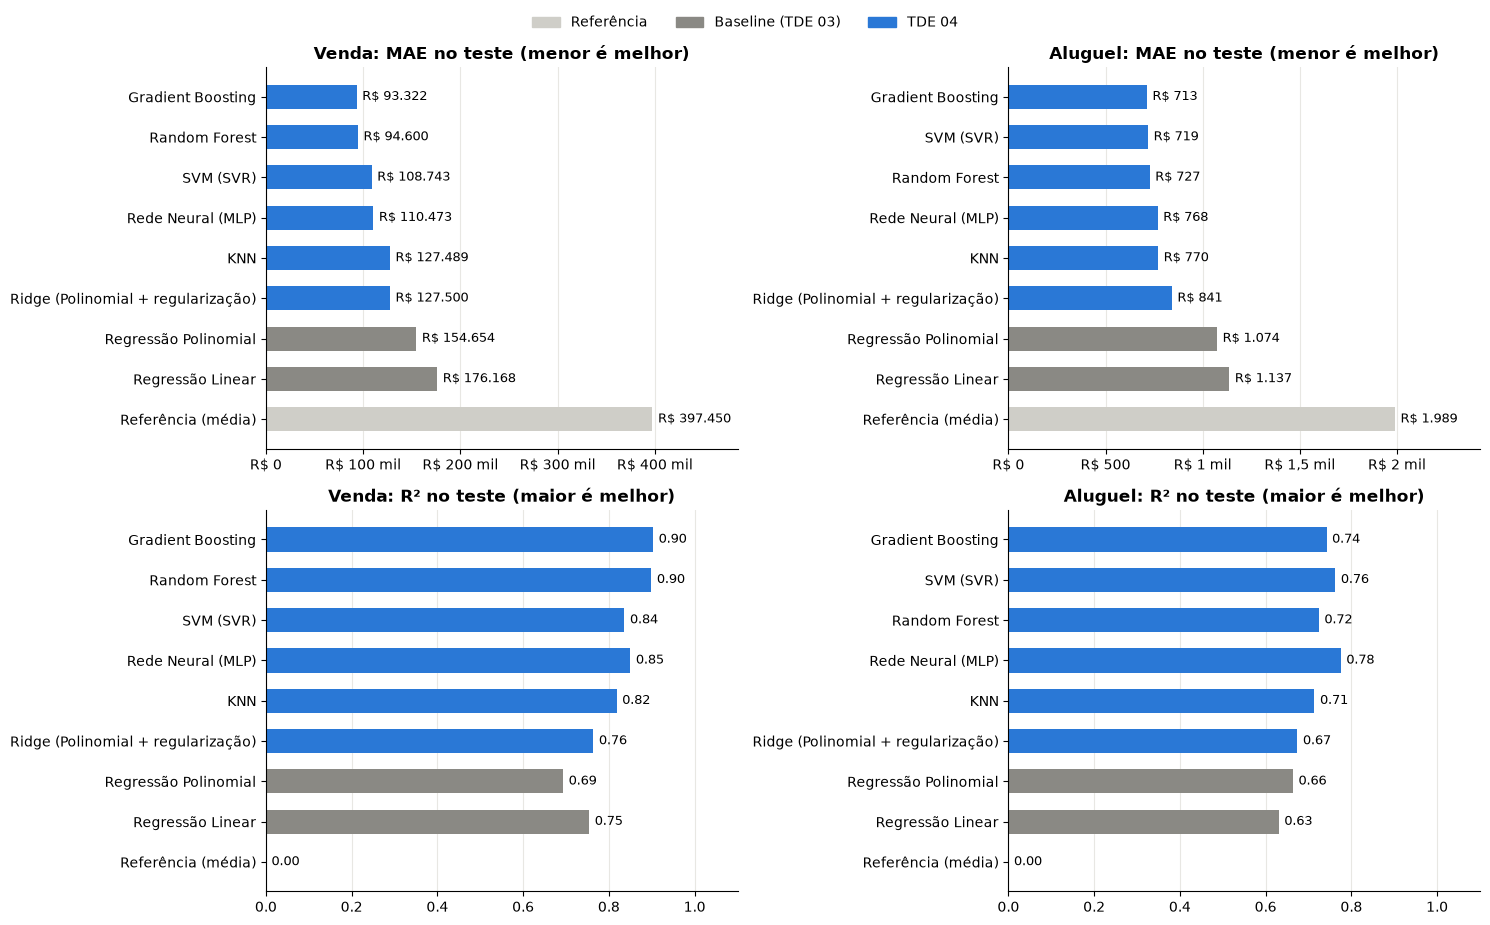

In [21]:
cores_etapa = {"Referência": CINZA_CLARO, "Baseline (TDE 03)": CINZA, "TDE 04": AZUL}

fig, eixos = plt.subplots(2, 2, figsize=(15, 9))

for coluna, tipo in enumerate(["Venda", "Aluguel"]):
    # Ordena do pior para o melhor MAE (no gráfico de barras deitadas, o melhor fica em cima)
    t = tabela[tabela["Tipo"] == tipo].sort_values("MAE", ascending=False)
    cores = [cores_etapa[etapa] for etapa in t["Etapa"]]

    # MAE: menor é melhor
    eixo = eixos[0, coluna]
    barras = eixo.barh(t["Modelo"], t["MAE"], color=cores, height=0.6)
    eixo.bar_label(barras, labels=[reais(v) for v in t["MAE"]], padding=4, fontsize=9)
    eixo.set_title(f"{tipo}: MAE no teste (menor é melhor)")
    eixo.xaxis.set_major_formatter(FuncFormatter(reais_curto))
    eixo.margins(x=0.22)
    eixo.grid(axis="y", visible=False)

    # R²: maior é melhor (mesma ordem de modelos)
    eixo = eixos[1, coluna]
    r2 = t["R²"].clip(lower=0)   # a referência tem R² negativo muito pequeno (praticamente 0); mostramos como 0
    barras = eixo.barh(t["Modelo"], r2, color=cores, height=0.6)
    eixo.bar_label(barras, labels=[f"{v:.2f}" for v in r2], padding=4, fontsize=9)
    eixo.set_title(f"{tipo}: R² no teste (maior é melhor)")
    eixo.set_xlim(0, 1.1)
    eixo.grid(axis="y", visible=False)

legenda = [Patch(color=cor, label=etapa) for etapa, cor in cores_etapa.items()]
fig.legend(handles=legenda, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()
plt.show()

### 9.4 Treino x teste: algum modelo decorou os dados?

Se o R² no treino é muito maior que no teste, o modelo "decorou" parte do treino (**overfitting**).

In [22]:
overfitting = tabela[tabela["Etapa"] != "Referência"][["Tipo", "Modelo", "R² treino", "R²"]]
overfitting = overfitting.rename(columns={"R²": "R² teste"})
overfitting["Diferença"] = overfitting["R² treino"] - overfitting["R² teste"]
overfitting.round(2).reset_index(drop=True)

,Tipo,Modelo,R² treino,R² teste,Diferença
0,Venda,Regressão Linear,0.72,0.75,-0.03
1,Aluguel,Regressão Linear,0.61,0.63,-0.02
2,Venda,Regressão Polinomial,0.83,0.69,0.13
3,Aluguel,Regressão Polinomial,0.65,0.66,-0.01
4,Venda,Ridge (Polinomial + regularização),0.95,0.76,0.18
5,Aluguel,Ridge (Polinomial + regularização),0.82,0.67,0.15
6,Venda,SVM (SVR),0.96,0.84,0.12
7,Aluguel,SVM (SVR),0.84,0.76,0.08
8,Venda,Rede Neural (MLP),0.95,0.85,0.10
9,Aluguel,Rede Neural (MLP),0.86,0.78,0.08


### 9.5 Preço real x preço previsto

A linha tracejada é onde a previsão é igual ao preço real: quanto mais perto dela, melhor. À esquerda o melhor modelo
do baseline, à direita o modelo final (os dois gráficos lado a lado usam a mesma escala).

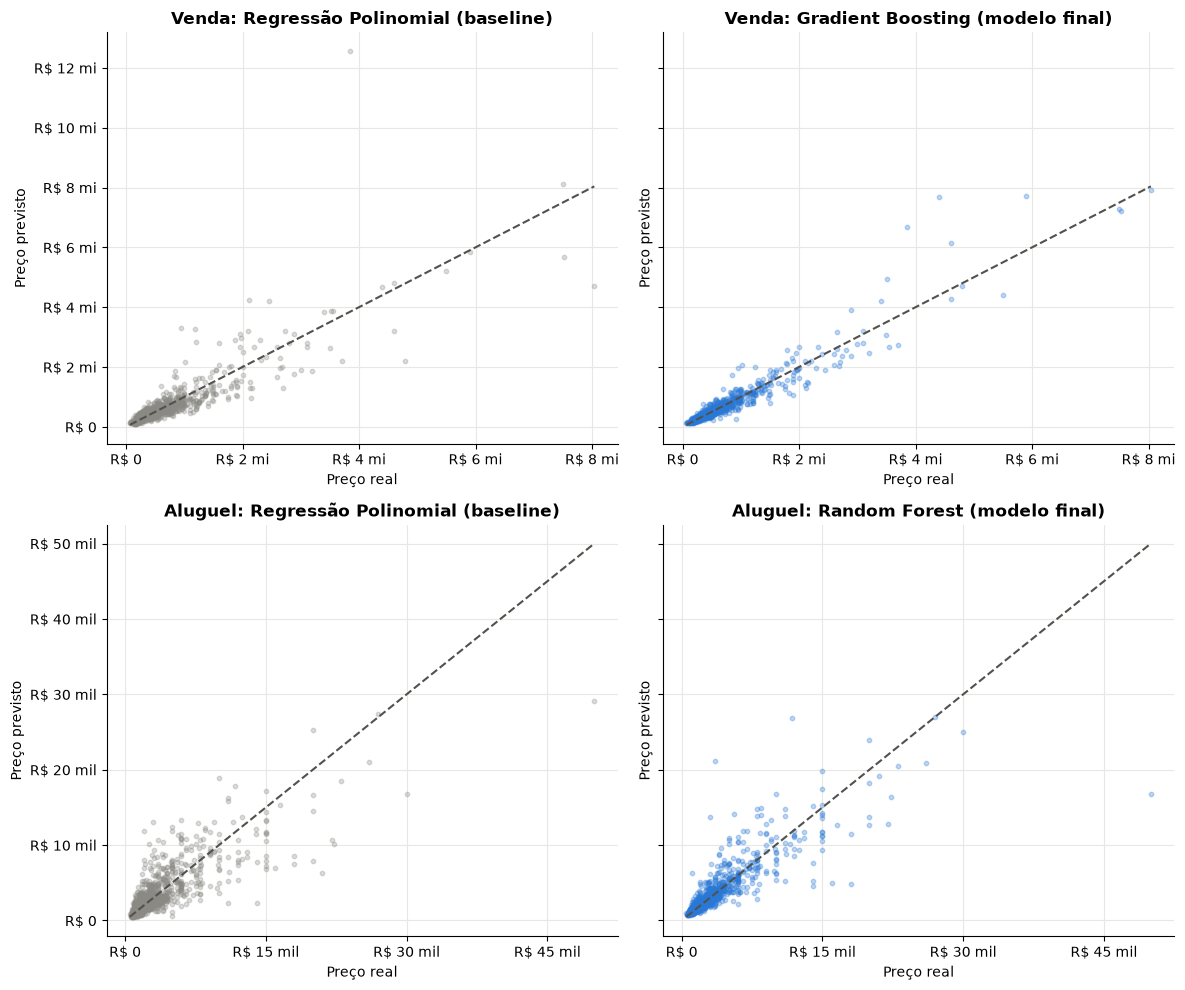

In [23]:
fig, eixos = plt.subplots(2, 2, figsize=(12, 10), sharex="row", sharey="row")

for linha, tipo in enumerate(["Venda", "Aluguel"]):
    y_real = teste[tipo]["Price"]
    for coluna, (nome, cor) in enumerate([(melhor_baseline[tipo], CINZA), (modelo_final[tipo], AZUL)]):
        eixo = eixos[linha, coluna]
        eixo.scatter(y_real, previsoes[(tipo, nome)], alpha=0.3, s=10, color=cor)
        eixo.plot([y_real.min(), y_real.max()], [y_real.min(), y_real.max()],
                  color=CINZA_ESCURO, linestyle="--", linewidth=1.5)
        etapa = "baseline" if coluna == 0 else "modelo final"
        eixo.set_title(f"{tipo}: {nome} ({etapa})")
        eixo.set_xlabel("Preço real")
        eixo.set_ylabel("Preço previsto")
        eixo.xaxis.set_major_formatter(FuncFormatter(reais_curto))
        eixo.yaxis.set_major_formatter(FuncFormatter(reais_curto))
        eixo.xaxis.set_major_locator(MaxNLocator(5))

plt.tight_layout()
plt.show()

### 9.6 Onde os modelos erram: erro por faixa de preço

VENDA — baseline: Regressão Polinomial | modelo final: Gradient Boosting


,Imóveis no teste,MAE baseline,MAE modelo final,Melhora
Price,,,,
até R$ 500 mil,756,R$ 69.090,R$ 40.213,42%
R$ 500 mil a 1 mi,295,R$ 162.159,R$ 108.732,33%
acima de R$ 1 mi,138,R$ 607.349,R$ 351.323,42%


ALUGUEL — baseline: Regressão Polinomial | modelo final: Random Forest


,Imóveis no teste,MAE baseline,MAE modelo final,Melhora
Price,,,,
até R$ 2 mil,703,R$ 526,R$ 272,48%
R$ 2 mil a 5 mil,467,R$ 1.084,R$ 714,34%
acima de R$ 5 mil,173,R$ 3.272,R$ 2.611,20%


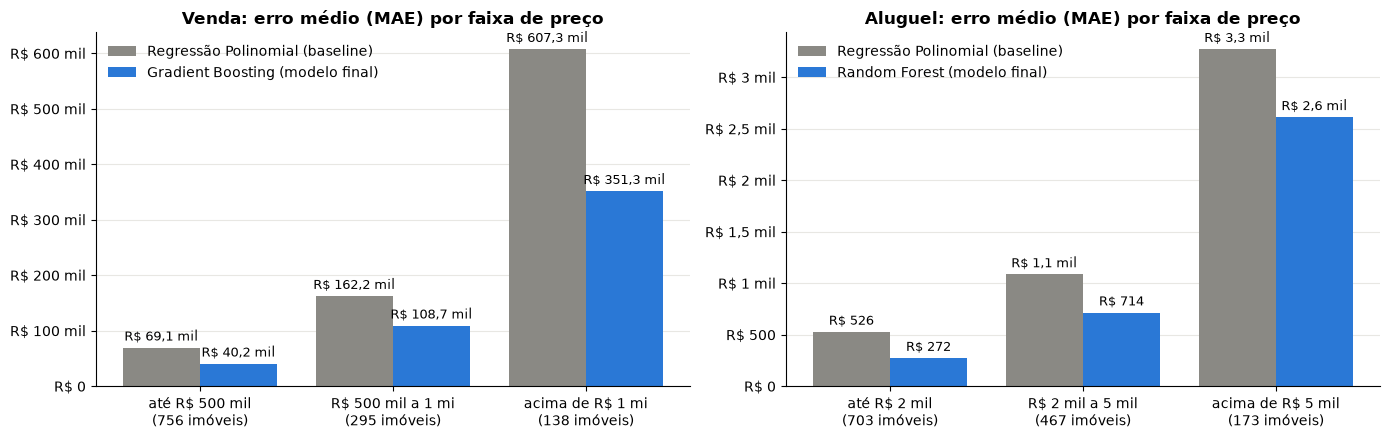

In [24]:
faixas = {
    "Venda": ([0, 500_000, 1_000_000, np.inf], ["até R$ 500 mil", "R$ 500 mil a 1 mi", "acima de R$ 1 mi"]),
    "Aluguel": ([0, 2_000, 5_000, np.inf], ["até R$ 2 mil", "R$ 2 mil a 5 mil", "acima de R$ 5 mil"]),
}

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))

for eixo, tipo in zip(eixos, ["Venda", "Aluguel"]):
    y_real = teste[tipo]["Price"]
    limites, nomes = faixas[tipo]
    faixa = pd.cut(y_real, bins=limites, labels=nomes)

    erro_baseline = (y_real - previsoes[(tipo, melhor_baseline[tipo])]).abs()
    erro_final = (y_real - previsoes[(tipo, modelo_final[tipo])]).abs()

    por_faixa = pd.DataFrame({
        "Imóveis no teste": faixa.value_counts(sort=False),
        "MAE baseline": erro_baseline.groupby(faixa, observed=False).mean(),
        "MAE modelo final": erro_final.groupby(faixa, observed=False).mean(),
    })
    por_faixa["Melhora"] = 1 - por_faixa["MAE modelo final"] / por_faixa["MAE baseline"]

    # Versão da tabela formatada para leitura
    tabela_faixa = por_faixa.copy()
    tabela_faixa["MAE baseline"] = tabela_faixa["MAE baseline"].map(reais)
    tabela_faixa["MAE modelo final"] = tabela_faixa["MAE modelo final"].map(reais)
    tabela_faixa["Melhora"] = tabela_faixa["Melhora"].map(lambda v: f"{v:.0%}")
    print(f"{tipo.upper()} — baseline: {melhor_baseline[tipo]} | modelo final: {modelo_final[tipo]}")
    display(tabela_faixa)

    # Gráfico: barras lado a lado (cinza = baseline, azul = modelo final)
    posicoes = np.arange(len(nomes))
    b1 = eixo.bar(posicoes - 0.2, por_faixa["MAE baseline"], width=0.4, color=CINZA,
                  label=f"{melhor_baseline[tipo]} (baseline)")
    b2 = eixo.bar(posicoes + 0.2, por_faixa["MAE modelo final"], width=0.4, color=AZUL,
                  label=f"{modelo_final[tipo]} (modelo final)")
    eixo.bar_label(b1, labels=[reais_curto(v) for v in por_faixa["MAE baseline"]], padding=3, fontsize=9)
    eixo.bar_label(b2, labels=[reais_curto(v) for v in por_faixa["MAE modelo final"]], padding=3, fontsize=9)
    eixo.set_xticks(posicoes, [f"{n}\n({q} imóveis)" for n, q in zip(nomes, por_faixa["Imóveis no teste"])])
    eixo.set_title(f"{tipo}: erro médio (MAE) por faixa de preço")
    eixo.yaxis.set_major_formatter(FuncFormatter(reais_curto))
    eixo.grid(axis="x", visible=False)
    eixo.legend(frameon=False)

plt.tight_layout()
plt.show()

### 9.7 O que o modelo final considera mais importante?

Modelos de árvores medem quanto cada variável ajudou a diminuir o erro nas perguntas das árvores
(`feature_importances_`, a soma dá 100%). Somamos as 96 colunas de distrito em uma só, para comparar com as outras.

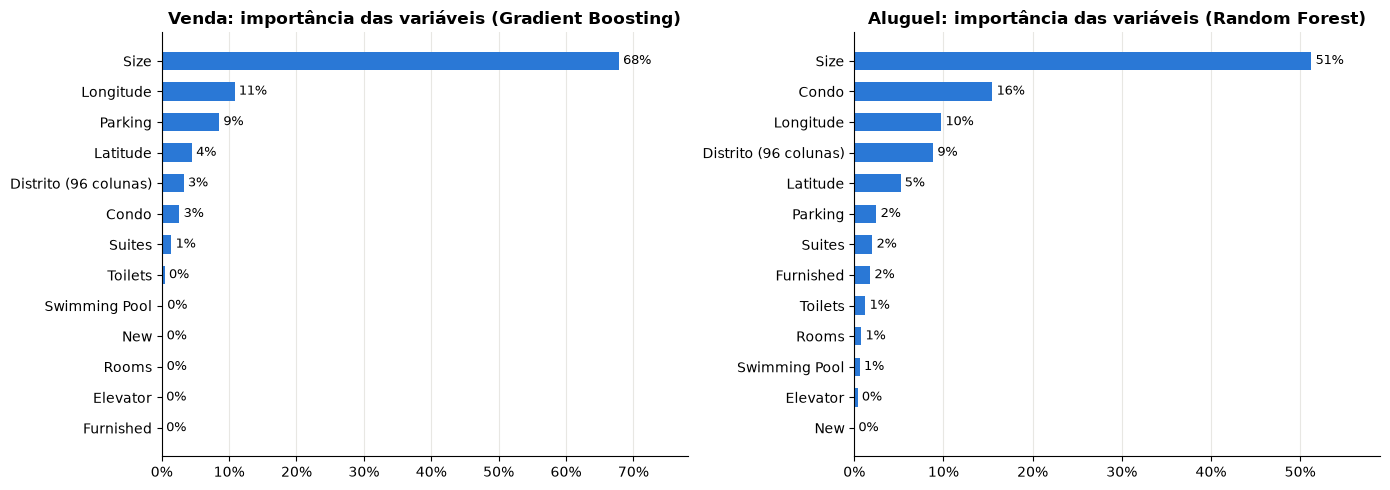

In [25]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

for eixo, tipo in zip(eixos, ["Venda", "Aluguel"]):
    modelo = modelos_treinados[(tipo, modelo_final[tipo])]
    arvores = modelo.regressor_.named_steps["modelo"]   # o modelo de árvores dentro do pipeline
    importancia = pd.Series(arvores.feature_importances_, index=colunas_tde04)

    resumo = importancia[colunas_originais].copy()
    resumo["Distrito (96 colunas)"] = importancia[colunas_distrito].sum()
    resumo = resumo.sort_values()

    barras = eixo.barh(resumo.index, resumo.values, color=AZUL, height=0.6)
    eixo.bar_label(barras, labels=[f"{v:.0%}" for v in resumo.values], padding=3, fontsize=9)
    eixo.set_title(f"{tipo}: importância das variáveis ({modelo_final[tipo]})")
    eixo.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0%}"))
    eixo.margins(x=0.15)
    eixo.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

### 9.8 Quanto o distrito ajudou cada modelo?

Treinamos de novo cada modelo do TDE 04 com os **mesmos hiperparâmetros**, mas **sem as colunas de distrito**
(só as 12 variáveis originais), e comparamos o MAE no teste.

In [26]:
modelos_tde04 = tabela[tabela["Etapa"] == "TDE 04"]["Modelo"].unique()
linhas = []

for tipo in ["Venda", "Aluguel"]:
    for nome in modelos_tde04:
        modelo = clone(modelos_treinados[(tipo, nome)])   # mesmo modelo e hiperparâmetros, ainda sem treinar
        modelo.fit(treino[tipo][colunas_originais], treino[tipo]["Price"])
        mae_sem = mean_absolute_error(teste[tipo]["Price"], modelo.predict(teste[tipo][colunas_originais]))
        mae_com = mean_absolute_error(teste[tipo]["Price"], previsoes[(tipo, nome)])
        linhas.append({"Tipo": tipo, "Modelo": nome, "MAE sem distrito": mae_sem,
                       "MAE com distrito": mae_com, "Melhora": 1 - mae_com / mae_sem})

efeito_distrito = pd.DataFrame(linhas)

# Versão da tabela formatada para leitura
tabela_distrito = efeito_distrito.copy()
tabela_distrito["MAE sem distrito"] = tabela_distrito["MAE sem distrito"].map(reais)
tabela_distrito["MAE com distrito"] = tabela_distrito["MAE com distrito"].map(reais)
tabela_distrito["Melhora"] = tabela_distrito["Melhora"].map(lambda v: f"{v:.0%}")
tabela_distrito

,Tipo,Modelo,MAE sem distrito,MAE com distrito,Melhora
0,Venda,Ridge (Polinomial + regularização),R$ 162.718,R$ 127.500,22%
1,Venda,SVM (SVR),R$ 121.712,R$ 108.743,11%
2,Venda,Rede Neural (MLP),R$ 128.840,R$ 110.473,14%
3,Venda,Random Forest,R$ 95.855,R$ 94.600,1%
4,Venda,Gradient Boosting,R$ 97.408,R$ 93.322,4%
5,Venda,KNN,R$ 131.194,R$ 127.489,3%
6,Aluguel,Ridge (Polinomial + regularização),R$ 1.048,R$ 841,20%
7,Aluguel,SVM (SVR),R$ 897,R$ 719,20%
8,Aluguel,Rede Neural (MLP),R$ 820,R$ 768,6%
9,Aluguel,Random Forest,R$ 743,R$ 727,2%


### 9.9 Exemplos de previsões

Alguns imóveis do teste, com o preço real e o que cada modelo previu.

In [27]:
for tipo in ["Venda", "Aluguel"]:
    exemplos = teste[tipo].sample(6, random_state=1)
    linear = modelos_treinados[(tipo, "Regressão Linear")].predict(exemplos[colunas_originais])
    final = modelos_treinados[(tipo, modelo_final[tipo])].predict(exemplos[colunas_tde04])

    print(tipo.upper())
    display(pd.DataFrame({
        "Distrito": exemplos["Distrito"],
        "Tamanho (m²)": exemplos["Size"],
        "Quartos": exemplos["Rooms"],
        "Vagas": exemplos["Parking"],
        "Preço real": exemplos["Price"].map(reais),
        "Regressão Linear (TDE 03)": [reais(v) for v in linear],
        f"{modelo_final[tipo]} (TDE 04)": [reais(v) for v in final],
    }).reset_index(drop=True))

VENDA


,Distrito,Tamanho (m²),Quartos,Vagas,Preço real,Regressão Linear (TDE 03),Gradient Boosting (TDE 04)
0,Pinheiros,107,3,1,R$ 840.000,R$ 780.214,R$ 956.833
1,Bom Retiro,70,2,1,R$ 340.000,R$ 508.301,R$ 488.957
2,Ipiranga,48,2,1,R$ 365.000,R$ 200.619,R$ 362.105
3,Bom Retiro,91,3,1,R$ 330.000,R$ 514.765,R$ 546.472
4,Itaim Bibi,98,2,1,R$ 1.049.000,R$ 850.784,R$ 1.134.124
5,Ermelino Matarazzo,66,2,1,R$ 350.000,R$ 328.082,R$ 347.483


ALUGUEL


,Distrito,Tamanho (m²),Quartos,Vagas,Preço real,Regressão Linear (TDE 03),Random Forest (TDE 04)
0,Vila Matilde,35,1,1,R$ 1.100,R$ 1.198,R$ 1.040
1,Perdizes,140,3,3,R$ 4.500,R$ 6.649,R$ 5.628
2,Cursino,62,3,1,R$ 1.160,R$ 916,R$ 1.369
3,Sacomã,40,1,1,R$ 1.000,R$ 1.904,R$ 1.248
4,Alto de Pinheiros,220,4,3,R$ 12.000,R$ 8.888,R$ 11.193
5,São Lucas,65,3,2,R$ 1.100,R$ 1.372,R$ 1.616


## 10. Discussão dos resultados

### 10.1 Batemos as metas do TDE 03?

No TDE 03 definimos como meta superar o melhor resultado do baseline em MAE e em R².

In [28]:
for tipo in ["Venda", "Aluguel"]:
    t = tabela[tabela["Tipo"] == tipo]
    baseline = t[t["Etapa"] == "Baseline (TDE 03)"]
    final = t[t["Modelo"] == modelo_final[tipo]].iloc[0]

    meta_mae = baseline["MAE"].min()
    meta_r2 = baseline["R²"].max()
    preco_medio = teste[tipo]["Price"].mean()

    print(f"{tipo.upper()} — modelo final: {modelo_final[tipo]}")
    print(f"  MAE: meta abaixo de {reais(meta_mae)} -> {reais(final['MAE'])} "
          f"({'atingida' if final['MAE'] < meta_mae else 'NÃO atingida'}; erro {1 - final['MAE'] / meta_mae:.0%} menor)")
    print(f"  R²:  meta acima de {meta_r2:.2f} -> {final['R²']:.2f} "
          f"({'atingida' if final['R²'] > meta_r2 else 'NÃO atingida'})")
    print(f"  Erro médio em % do preço médio: baseline {meta_mae / preco_medio:.0%} -> final {final['MAE'] / preco_medio:.0%}")
    print()

VENDA — modelo final: Gradient Boosting
  MAE: meta abaixo de R$ 154.654 -> R$ 93.322 (atingida; erro 40% menor)
  R²:  meta acima de 0.75 -> 0.90 (atingida)
  Erro médio em % do preço médio: baseline 26% -> final 16%

ALUGUEL — modelo final: Random Forest
  MAE: meta abaixo de R$ 1.074 -> R$ 727 (atingida; erro 32% menor)
  R²:  meta acima de 0.66 -> 0.72 (atingida)
  Erro médio em % do preço médio: baseline 35% -> final 24%



### 10.2 A regularização "segurou" a Regressão Polinomial?

No TDE 03, a Polinomial previu **R\$ 12,6 milhões** para um apartamento de 620 m² que custa R\$ 3,85 milhões (ele é
maior que qualquer imóvel do treino). Vamos ver o que cada modelo prevê para esse mesmo imóvel:

In [29]:
# O imóvel em que a Regressão Polinomial mais errou na venda
y_venda = teste["Venda"]["Price"].to_numpy()
i = np.argmax(np.abs(y_venda - previsoes[("Venda", "Regressão Polinomial")]))
imovel = teste["Venda"].iloc[i]

print(f"Imóvel: {imovel['Size']} m², {imovel['Rooms']} quartos, {imovel['Parking']} vagas, distrito {imovel['Distrito']}")
print(f"Maior imóvel do treino: {treino['Venda']['Size'].max()} m²")
print(f"Preço real: {reais(imovel['Price'])}")
print()
for nome in tabela[(tabela["Tipo"] == "Venda") & (tabela["Etapa"] != "Referência")]["Modelo"]:
    previsto = previsoes[("Venda", nome)][i]
    print(f"{nome:36s} previu {reais(previsto):>14s}  (erro de {reais(abs(previsto - imovel['Price']))})")

Imóvel: 620 m², 4 quartos, 5 vagas, distrito Alto de Pinheiros
Maior imóvel do treino: 420 m²
Preço real: R$ 3.850.000

Regressão Linear                     previu   R$ 6.832.397  (erro de R$ 2.982.397)
Regressão Polinomial                 previu  R$ 12.563.399  (erro de R$ 8.713.399)
Ridge (Polinomial + regularização)   previu  R$ 12.102.924  (erro de R$ 8.252.924)
SVM (SVR)                            previu   R$ 8.781.692  (erro de R$ 4.931.692)
Rede Neural (MLP)                    previu   R$ 9.508.816  (erro de R$ 5.658.816)
Random Forest                        previu   R$ 6.988.869  (erro de R$ 3.138.869)
Gradient Boosting                    previu   R$ 6.690.254  (erro de R$ 2.840.254)
KNN                                  previu   R$ 6.541.392  (erro de R$ 2.691.392)


**Não.** O Ridge ainda previu cerca de R\$ 12,1 milhões. A regularização diminui os pesos, mas esse imóvel tem 620 m²,
bem maior que o maior imóvel do treino (420 m²). Fora da faixa que viu no treino, a curva polinomial continua
"subindo" sem controle. Isso se chama **extrapolação**.

As árvores (Random Forest e Gradient Boosting) erraram bem menos que os modelos polinomiais, a SVM e a Rede Neural
(previram perto de R\$ 7 milhões), porque só conseguem prever valores parecidos com os preços que viram no treino.
O KNN, pelo mesmo motivo (ele tira a média de preços que já existem), previu R\$ 6,5 milhões.
A Regressão Linear simples ficou parecida (R\$ 6,8 milhões): uma reta extrapola de forma mais "comportada" que uma
curva. Mesmo assim, todos erraram cerca de R\$ 3 milhões ou mais.
Lição: **nenhum modelo é confiável para um imóvel muito diferente dos que existem no treino.**

### 10.3 O que mais ajudou?

1. **Modelos não lineares, principalmente os de árvores.** Os seis modelos novos superaram o baseline, e os
   melhores foram o Gradient Boosting e a Random Forest. Uma árvore faz perguntas como "Longitude < -46,65?" e
   "Size > 120?", então consegue "desenhar" no mapa as regiões caras e baratas, coisa que uma equação de regressão
   linear não consegue.
2. **O distrito (one-hot).** A seção 9.8 mostra que o distrito ajudou muito os modelos que dependem de pesos e
   distâncias. Na venda, o erro caiu 22% no Ridge, 14% na Rede Neural e 11% na SVM. Nas árvores a melhora foi
   pequena (1% a 4%), porque elas já aprendem as regiões sozinhas pela latitude e pela longitude.
3. **O que pesa no preço.** Pela importância das variáveis (seção 9.7), o **tamanho** é a variável mais importante
   (68% na venda e 51% no aluguel). Somando latitude, longitude e distrito, a **localização** fica com
   cerca de 19% na venda e 24% no aluguel. No aluguel, o **condomínio** também pesa bastante (16%).

### 10.4 SVM, Rede Neural e KNN

- As duas superaram o baseline com folga. Na venda, a SVM errou em média R\$ 108.743 e a Rede Neural R\$ 110.473,
  contra R\$ 154.654 da Polinomial.
- No aluguel, a SVM ficou a apenas R\$ 6 do melhor MAE (R\$ 719 contra R\$ 713), e a Rede Neural teve o **maior R²**
  (0,78) e o **menor RMSE** (R\$ 1.617) de todos os modelos.
- As duas ganharam bastante com o distrito: sem ele, a SVM erraria R\$ 121.712 na venda (seção 9.8): ainda melhor que
  o baseline, mas o distrito diminuiu esse erro em 11%. Elas também precisam da normalização, porque trabalham com distâncias e pesos (seção 6.1).
- **KNN** (não visto em sala): errou em média R\$ 127.489 na venda e R\$ 770 no aluguel. Ficou bem melhor que o
  baseline, mas atrás dos outros modelos novos (na venda, praticamente empatado com o Ridge). Com
  `weights="distance"`, cada imóvel do treino é o seu próprio vizinho mais próximo, por isso o R² no treino é 1,00:
  ele "decora" o treino por construção. O distrito ajudou menos o KNN (3% na venda e 9% no aluguel) do que a SVM
  e a Rede Neural.

### 10.5 No aluguel, qual é o melhor modelo?

No aluguel, quatro modelos ficaram muito perto no MAE (de R\$ 713 a R\$ 768). Pelo **MAE** no teste, nossa métrica
principal, o Gradient Boosting ganha (R\$ 713), com a SVM (R\$ 719) e a Random Forest (R\$ 727) logo atrás. Pelo
**RMSE e pelo R²**, a Rede Neural (0,78) e a SVM (0,76) ganham. Como o RMSE e o R² pesam muito os erros grandes, isso
quer dizer que a Rede Neural não erra menos na média, mas comete menos erros muito grandes.

Na validação cruzada, a Random Forest (R\$ 735) e o Gradient Boosting (R\$ 741) ficaram praticamente empatados, e
seguimos a regra que definimos antes de olhar o teste: menor MAE na validação, ou seja, a **Random Forest**. No teste,
o Gradient Boosting (R\$ 713) e a SVM (R\$ 719) tiveram um MAE um pouco menor que a Random Forest (R\$ 727). Essas
diferenças são pequenas e poderiam mudar com outra divisão dos dados.

### 10.6 Overfitting

- As árvores têm R² no treino perto de 1 (0,97 a 1,00) e menor no teste (0,90 na venda; 0,72 e 0,74 no aluguel):
  elas praticamente **decoram** o treino. Na Random Forest, cada árvore cresce até sobrar 1 imóvel por folha
  (`min_samples_leaf=1`). No Gradient Boosting, as 500 árvores corrigindo o erro uma depois da outra acabam ajustando
  quase todo o treino. Na venda isso não atrapalhou (diferença de 0,09), mas no aluguel a diferença é de 0,24 a 0,25.
  A validação cruzada testou árvores mais simples (`min_samples_leaf=3` e `max_depth=3`) e preferiu as maiores,
  então só limitar o tamanho das árvores provavelmente não resolve: o aluguel continua difícil (seção 10.7).
- O Ridge também ficou com uma diferença grande (0,95 no treino e 0,76 no teste da venda): com quase 6 mil
  variáveis polinomiais, ele também decora parte do treino.
- A SVM e a Rede Neural tiveram diferença de 0,08 a 0,12: no aluguel, bem menos que as árvores; na venda,
  parecido com elas.

### 10.7 Venda x aluguel

Mesmo com a melhora, o **aluguel continua mais difícil de prever**: o erro do modelo final é 24% do preço médio no
aluguel, contra 16% na venda, e o R² é 0,72 contra 0,90. Como no TDE 03, nossa hipótese é que o aluguel depende mais
de coisas que não estão na base, como estado de conservação, andar, vista e qualidade da mobília.

### 10.8 Limitações

- **Imóveis caros:** acima de R\$ 1 milhão o modelo final ainda erra, em média, R\$ 351.323 na venda; no aluguel,
  acima de R\$ 5 mil, erra R\$ 2.611. São poucos imóveis desse tipo para o modelo aprender.
- **Extrapolação:** nenhum modelo acerta imóveis muito diferentes dos que existem no treino (o caso dos 620 m²).
- **A base:** é de abril de 2019, só tem apartamentos e só da cidade de São Paulo.
- **Grades pequenas:** testamos poucas combinações de hiperparâmetros, para o notebook rodar em poucos minutos.
  Alguns valores escolhidos ficaram na ponta da grade (Gradient Boosting com `learning_rate=0.1` e `max_depth=5`,
  Rede Neural com `alpha=1`, SVM com ε = 0,01), então talvez existam valores melhores fora dela.
- **O teste já era conhecido:** é o mesmo do TDE 03, e algumas ideias desta etapa (como a regularização) vieram de
  erros que vimos nele (o imóvel de 620 m²). A escolha dos modelos foi feita só pela validação cruzada, mas o
  resultado no teste pode estar um pouco otimista.
- **Uma única divisão treino/teste:** diferenças pequenas no teste (como R\$ 713 contra R\$ 727 no aluguel) podem
  ser sorte da divisão.
- A importância das variáveis das árvores é uma medida aproximada.

### 10.9 Próximos passos

1. Aplicar **log no preço** para diminuir o peso da cauda longa (estava nos próximos passos do TDE 03 e ainda não testamos);
2. Testar **XGBoost** e **LightGBM**, versões mais rápidas do Gradient Boosting;
3. **Combinar modelos**, por exemplo a média do Gradient Boosting com a Rede Neural;
4. Conseguir **mais variáveis**, como andar, idade do prédio e estado de conservação.

## 11. Conclusão

- Partimos do baseline do TDE 03 (Regressão Linear e Polinomial) e testamos **seis modelos novos**: Ridge, SVM,
  Rede Neural, Random Forest, Gradient Boosting e KNN (os dois últimos não foram vistos em sala; o boosting foi
  visto só com o AdaBoost).
- Mudamos também os dados e o treino: **distrito com one-hot**, **normalização** e **hiperparâmetros escolhidos com
  validação cruzada**, sempre com a mesma divisão de treino e teste do baseline.
- **Todos os modelos novos superaram o baseline**, na venda e no aluguel.
- **Modelo final:**
  - **Venda: Gradient Boosting**, MAE de R\$ 93.322 (40% menor que o baseline) e R² de 0,90;
  - **Aluguel: Random Forest**, MAE de R\$ 727 (32% menor que o baseline) e R² de 0,72.
- As duas metas do TDE 03 foram atingidas.
- Principais lições: modelos de árvores lidam bem com a localização por regiões (neles, quase toda a melhora veio
  do próprio algoritmo); representar bem os dados também importa, pois o distrito reduziu o erro em até 22% no Ridge,
  na SVM e na Rede Neural; e nenhum modelo acerta bem imóveis muito diferentes dos que viu no treino.